In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import analysis_utils as base

set_size = base.set_size
pgf_with_latex = base.pgf_with_latex
doc_width_pt = base.doc_width_pt

plt.rcParams.update(pgf_with_latex)

sns.set_palette("colorblind")

CI95_Z = 1.96  # normal-approximation 95% CI half-width, in units of SEM
N_TAIL_EVALS = 3  # matches compute_final_values elsewhere in this repo
AGGREGATE = "iqm"  # across seeds: "iqm" / "median" (95% bootstrap CI) or "mean" (95% normal CI)
N_BOOTSTRAP = 10000

# Fetched with:
#   python fetch_wandb_minatar.py --project minatar-icot-nov06-g0.999 --gamma 0.99999 --out minatar-icot-g0.99999.csv
CSV_PATH = "minatar-icot-g0.99999.csv"
GAMMA = 0.99999

ENVS = (
    ("Asterix-MinAtar", "Asterix"),
    ("Breakout-MinAtar", "Breakout"),
    ("Freeway-MinAtar", "Freeway"),
    ("Seaquest-MinAtar", "Seaquest"),
    ("SpaceInvaders-MinAtar", "Space Invaders"),
)
PREFIXES = (
    ("actor", "Training"),  # last N_TAIL_EVALS evals
    ("absolute", "Evaluation"),  # absolute metric: best checkpoint, 10x episodes
)
METRIC = "episode_discounted_return"
Y_LABEL = "Disc. return"

In [2]:
df = pd.read_csv(CSV_PATH)
df = df[(df["state"] == "finished") & ~df["sgh"]]
df = df[np.isclose(df["gamma"], GAMMA)]
print(f"arch={df['arch'].unique()}, gamma={df['gamma'].unique()}, runs={df['run_id'].nunique()}")
print(df.groupby(["env", "min_steps", "max_steps"])["run_id"].nunique().unstack(["min_steps", "max_steps"]))

arch=['Transformer-CoT'], gamma=[0.99999], runs=150
min_steps              1     2  3  4  5
max_steps              1  5  2  3  4  5
env                                    
Asterix-MinAtar        5  5  5  5  5  5
Breakout-MinAtar       5  5  5  5  5  5
Freeway-MinAtar        5  5  5  5  5  5
Seaquest-MinAtar       5  5  5  5  5  5
SpaceInvaders-MinAtar  5  5  5  5  5  5


In [3]:
def aggregate(v, axis=-1):
    """AGGREGATE of v along `axis`. "iqm" is the interquartile mean: the mean of the
    middle 50% after dropping int(n/4) values from each end (scipy.stats.trim_mean(v, 0.25))."""
    v = np.asarray(v, dtype=float)
    if AGGREGATE == "mean":
        return v.mean(axis=axis)
    if AGGREGATE == "median":
        return np.median(v, axis=axis)
    if AGGREGATE == "iqm":
        n = v.shape[axis]
        k = int(0.25 * n)
        return np.take(np.sort(v, axis=axis), np.arange(k, n - k), axis=axis).mean(axis=axis)
    raise ValueError(f"Unknown AGGREGATE {AGGREGATE!r}")


def center_and_ci(v, rng=np.random.default_rng(0)):
    """(center, lo, hi) of v across seeds: AGGREGATE="mean" gives the mean with a
    normal-approximation 95% CI, "median"/"iqm" a percentile-bootstrap 95% CI."""
    v = np.asarray(v, dtype=float)
    n = len(v)
    if AGGREGATE == "mean":
        c = v.mean()
        h = CI95_Z * v.std(ddof=1) / np.sqrt(n) if n > 1 else 0.0
        return c, c - h, c + h
    c = aggregate(v)
    if n <= 1:
        return c, c, c
    boot = aggregate(rng.choice(v, size=(N_BOOTSTRAP, n), replace=True), axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return c, lo, hi


def compute_final_values(sub, metric, n_tail=N_TAIL_EVALS):
    """Per-run final performance: mean of the last n_tail eval points."""
    tail = sub.sort_values("eval_idx").groupby("run_id").tail(n_tail)
    return (
        tail.groupby("run_id")
        .agg(value=(metric, "mean"), min_steps=("min_steps", "first"), max_steps=("max_steps", "first"))
        .dropna(subset=["value"])
        .reset_index()
    )


def budget_stats(sub, metric):
    """DataFrame[min_steps, max_steps, center, lo, hi, n], one row per budget present in `sub`."""
    final = compute_final_values(sub, metric)
    rows = []
    for (mn, mx), g in final.groupby(["min_steps", "max_steps"]):
        center, lo, hi = center_and_ci(g["value"])
        rows.append({"min_steps": mn, "max_steps": mx, "center": center, "lo": lo, "hi": hi, "n": len(g)})
    return pd.DataFrame(rows)


def budget_label(min_steps, max_steps):
    return f"uniform={min_steps}" if min_steps == max_steps else f"adaptive[{min_steps}-{max_steps}]"


def latex_label(budget):
    if "uniform" in budget:
        return "$c = {}$".format(budget.split("=")[-1])
    min_c, max_c = budget.split("[")[1][:-1].split("-")
    return "$c \\in [{}, {}]$".format(min_c, max_c)

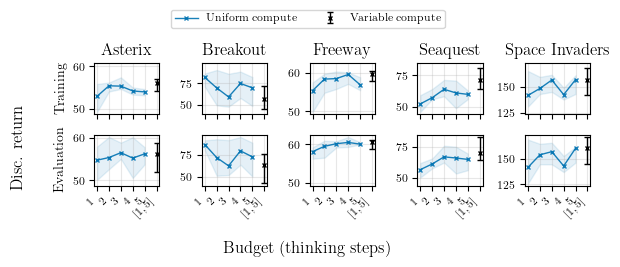

In [4]:
# Final disc. return vs. budget: rows = training / evaluation, columns = env.
uniform_budgets = sorted(df.loc[df["min_steps"] == df["max_steps"], "min_steps"].unique())
adaptive_budgets = df.loc[df["min_steps"] != df["max_steps"], ["min_steps", "max_steps"]].drop_duplicates()
labels = [str(b) for b in uniform_budgets] + [f"$[{mn},{mx}]$" for mn, mx in adaptive_budgets.itertuples(index=False)]
color_uniform = sns.color_palette("colorblind")[0]
color_adaptive = (0.0, 0.0, 0.0)

nrows, ncols = len(PREFIXES), len(ENVS)
figsize = set_size(doc_width_pt, fraction=0.95, subplots=(nrows, ncols), use_golden_ratio=False)
fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=True, sharey="col", squeeze=False)
for row_i, (prefix, prefix_title) in enumerate(PREFIXES):
    for col_i, (env, env_title) in enumerate(ENVS):
        ax = axes[row_i, col_i]
        stats = budget_stats(df[df["env"] == env], f"{prefix}/{METRIC}/mean")

        uni = stats[stats["min_steps"] == stats["max_steps"]].sort_values("min_steps")
        xs = [uniform_budgets.index(b) for b in uni["min_steps"]]
        ax.plot(xs, uni["center"], marker="x", color=color_uniform, ms=3, linewidth=1, alpha=0.9, label="Uniform compute")
        ax.fill_between(xs, uni["lo"], uni["hi"], color=color_uniform, alpha=0.1)

        ada = stats[stats["min_steps"] != stats["max_steps"]]
        if not ada.empty:
            ax.errorbar(
                [len(uniform_budgets)] * len(ada), ada["center"],
                yerr=np.stack([ada["center"] - ada["lo"], ada["hi"] - ada["center"]]),
                marker="x", color=color_adaptive, ms=3, linewidth=1, capsize=2, linestyle="none",
                label="Variable compute",
            )

        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=45, ha="right")
        ax.grid(True, alpha=0.3)
        if row_i == 0:
            ax.set_title(env_title)
    axes[row_i, 0].set_ylabel(prefix_title)

handles, leg_labels = axes[0, 0].get_legend_handles_labels()
fig.supxlabel("Budget (thinking steps)", y=0.04)
fig.supylabel(Y_LABEL, x=0.0)
fig.legend(handles, leg_labels,
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=6,
    borderaxespad=0.0,
    frameon=True,
)
fig.tight_layout()
fig.savefig(f"analysis-minatar-budget-g{GAMMA:g}.pdf", dpi=600, format="pdf", bbox_inches="tight")
plt.show()

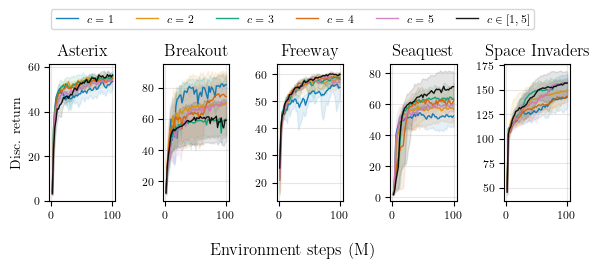

In [5]:
# Learning curves: disc. return over training, one panel per env.
all_budget_labels = sorted(
    {budget_label(mn, mx) for mn, mx in df[["min_steps", "max_steps"]].drop_duplicates().itertuples(index=False)},
    key=lambda b: (b.startswith("adaptive"), b),
)
palette = dict(zip(all_budget_labels, sns.color_palette("colorblind", n_colors=len(all_budget_labels))))
palette["adaptive[1-5]"] = (0.0, 0.0, 0.0)

PANEL_PREFIX = "actor"  # "actor" (training rollouts) or "evaluator" (per-checkpoint eval)

nrows, ncols = 1, len(ENVS)
figsize = set_size(doc_width_pt, fraction=0.95, subplots=(nrows * 2, ncols), use_golden_ratio=False)
fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=True, sharey=False, squeeze=False)
axes = axes.flatten()
metric = f"{PANEL_PREFIX}/{METRIC}/mean"
for ax, (env, env_title) in zip(axes, ENVS):
    sub = df[df["env"] == env]
    for (mn, mx), g in sorted(sub.groupby(["min_steps", "max_steps"]), key=lambda kv: (kv[0][0] != kv[0][1], kv[0])):
        budget = budget_label(mn, mx)
        curves = g.pivot_table(index="eval_idx", columns="run_id", values=metric)
        xs = np.linspace(0, g["total_timesteps"].iat[0], len(curves) + 1)[1:] / 1e6
        cis = np.array([center_and_ci(row.dropna().values) for _, row in curves.iterrows()])
        color = palette[budget]
        ax.plot(xs, cis[:, 0], color=color, linewidth=1, alpha=0.9, label=latex_label(budget))
        ax.fill_between(xs, cis[:, 1], cis[:, 2], color=color, alpha=0.1)
    ax.set_title(env_title)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel(Y_LABEL)

handles, leg_labels = axes[0].get_legend_handles_labels()
fig.supxlabel("Environment steps (M)", y=0.04)
fig.legend(handles, leg_labels,
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=6,
    borderaxespad=0.0,
    frameon=True,
)
fig.tight_layout()
fig.savefig(f"analysis-minatar-curves-g{GAMMA:g}.pdf", dpi=600, format="pdf", bbox_inches="tight")
plt.show()